## Supervised Learning
## Project: Finding Donors for *CharityML*

## Project Overview

Nonprofit organizations often operate with limited resources, making it important to identify and prioritize potential donors. Machine Learning offers an opportunity to support this process by identifying patterns in demographics and employment-related data.

In this project, I explore how supervised machine learning algorithms can be used to predict whether an individual earns more than $50,000 annually. Using census data, I compare multiple classification models, evaluate their performance and optimize the most promising algorithm.

The project demostrates how predictive analysis could support data-driven decision making in nonprofit fundraising.

## Project Objective

-Explore and preprocess census data to prepare it for machine learning

-Implement and compare multiple supervised classification algorithms.

-Evaluate model performance using accuracy and F-score.

-Optimize the selected model through hyperparameter tuning

-Analyze feature importance to identify influential predictors

-Interpret the results and dsicuss their potential applications and limitations

In [1]:
# Import libraries necessary for this project
import numpy as np
import pandas as pd
from time import time
from IPython.display import display

# Import supplementary visualization code visuals.py
import visuals as vs

# Pretty display for notebooks
%matplotlib inline

# Load the Census dataset
data = pd.read_csv("census.csv")

# Success - Display the first record
display(data.head(n=10))

,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40.0,United-States,<=50K
1,50,Self-emp-not-inc,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,13.0,United-States,<=50K
2,38,Private,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,40.0,United-States,<=50K
3,53,Private,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.0,0.0,40.0,United-States,<=50K
4,28,Private,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.0,0.0,40.0,Cuba,<=50K
5,37,Private,Masters,14.0,Married-civ-spouse,Exec-managerial,Wife,White,Female,0.0,0.0,40.0,United-States,<=50K
6,49,Private,9th,5.0,Married-spouse-absent,Other-service,Not-in-family,Black,Female,0.0,0.0,16.0,Jamaica,<=50K
7,52,Self-emp-not-inc,HS-grad,9.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,45.0,United-States,>50K
8,31,Private,Masters,14.0,Never-married,Prof-specialty,Not-in-family,White,Female,14084.0,0.0,50.0,United-States,>50K
9,42,Private,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,5178.0,0.0,40.0,United-States,>50K


In [2]:
feature_summary = pd.DataFrame({
    'Data Type': data.dtypes.astype(str),
    'Unique Values': data.nunique(),
    'Missing Values': data.isnull().sum()
})

feature_summary.index.name = 'Feature'

display(feature_summary)

,Data Type,Unique Values,Missing Values
Feature,,,
age,int64,74,0
workclass,object,7,0
education_level,object,16,0
education-num,float64,16,0
marital-status,object,7,0
occupation,object,14,0
relationship,object,6,0
race,object,5,0
sex,object,2,0


### Feature Exploration Summary

The dataset contains a combination of numerical and categorical features describing individuals' demographic backgrounds, education, employment, and financial characteristics.

This initial exploration helps identify the preprocessing steps required before model development. Numerical features may require scaling or transformation, while categorical features need to be encoded into a format suitable for machine learning algorithms.

Additionally, examining unique values and missing data helps identify potential data quality issues that could affect model performance.

In [3]:
n_records = len(data)
n_greater_50k = (data['income'] == '>50K').sum()
n_at_most_50k = (data['income'] == '<=50K').sum()

greater_percent = (n_greater_50k / n_records) * 100

print("Total number of records: {}".format(n_records))
print("Individuals making more than $50,000: {}".format(n_greater_50k))
print("Individuals making at most $50,000: {}".format(n_at_most_50k))
print("Percentage of individuals making more than $50,000: {}%".format(greater_percent))

Total number of records: 45222
Individuals making more than $50,000: 11208
Individuals making at most $50,000: 34014
Percentage of individuals making more than $50,000: 24.78439697492371%


### Exploratory Data Analysis: Income Distribution

To better understand the dataset, I began by examining the distribution of individuals across the two income categories: 

-Individuals earning more than %50,00 annually.

-Individuals earning $50,000 or less annually.

This initial analysis helps identify potential class imbalances, which are important to consider when evaluating classification models.

The following metrics were calculated:

- **Total Records (`n_records`):** Total number of individuals in the dataset.
- **Income > \$50K (`n_greater_50k`):** Number of individuals earning more than \$50,000 annually.
- **Income ≤ \$50K (`n_at_most_50k`):** Number of individuals earning \$50,000 or less annually.
- **Percentage Earning > $50K (`greater_percent`):** Proportion of individuals belonging to the higher-income category.

### Transforming Skewed Continuous Features

During data preprocessing, I identified two continuous features, `capital-gain` and `capital-loss`, that exhibit highly right-skewed distributions. Most observations are concentrated around zero, while a smaller number contain substantially higher values.

Highly skewed distributions can affect certain machine learning algorithms, particularly those sensitive to feature scales and extreme values.

To examine these distributions, I visualized both features using histograms before applying a logarithmic transformation.

The objective of this transformation is to reduce the influence of extreme values, compress the range of the data, and create a more manageable feature distribution for model training.

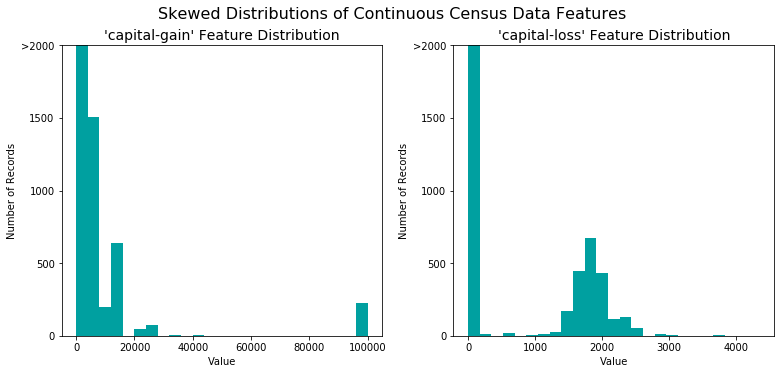

In [4]:
# Split the data into features and target label
income_raw = data['income']
features_raw = data.drop('income', axis = 1)

# Visualize skewed continuous features of original data
vs.distribution(data)

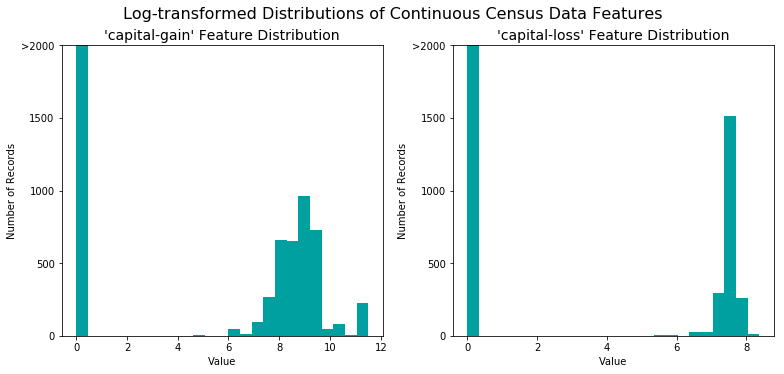

In [5]:
# Log-transform the skewed features
skewed = ['capital-gain', 'capital-loss']
features_log_transformed = pd.DataFrame(data = features_raw)
features_log_transformed[skewed] = features_raw[skewed].apply(lambda x: np.log(x + 1))

# Visualize the new log distributions
vs.distribution(features_log_transformed, transformed = True)

### Logarithmic Transformation

To address the highly right-skewed distributions of `capital-gain` and `capital-loss`, I applied a logarithmic transformation to both features.

This transformation compresses large values, reduces the range of extreme observations, and can improve the performance of certain machine learning algorithms.

Since both features contain zero values and the logarithm of zero is undefined, I used `np.log1p()`, which calculates the natural logarithm of each value plus one.

The following visualization compares the transformed feature distributions with their original distributions to assess the effect of the transformation.

### Normalizing Numerical Features

After transforming the skewed features, I applied Min-Max scaling to normalize the numerical variables.

Since numerical features can have significantly different ranges, certain machine learning algorithms may be disproportionately influenced by features with larger values. Scaling helps ensure that features are represented on a comparable scale.

I used `MinMaxScaler` from Scikit-learn to transform the numerical features into a range between 0 and 1 while preserving their relative ordering and the overall shape of their distributions.

This preprocessing step prepares the numerical features for model training, particularly for algorithms sensitive to differences in feature magnitude.

In [6]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
numerical = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

features_log_minmax_transform = pd.DataFrame(data = features_log_transformed)
features_log_minmax_transform[numerical] = scaler.fit_transform(features_log_transformed[numerical])


display(features_log_minmax_transform.head(n = 5))

Feature,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,0.301370,State-gov,Bachelors,0.800000,Never-married,Adm-clerical,Not-in-family,White,Male,0.667492,0.0,0.397959,United-States
1,0.452055,Self-emp-not-inc,Bachelors,0.800000,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.000000,0.0,0.122449,United-States
2,0.287671,Private,HS-grad,0.533333,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.000000,0.0,0.397959,United-States
3,0.493151,Private,11th,0.400000,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.000000,0.0,0.397959,United-States
4,0.150685,Private,Bachelors,0.800000,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.000000,0.0,0.397959,Cuba


**Observation:**

Min-Max scaling successfully transformed the numerical features to a common range of 0 to 1 without changing the overall shape of their distributions.

Unlike the logarithmic transformation applied earlier, normalization does not address skewness. Instead, it standardizes feature ranges, helping prevent differences in measurement scales from disproportionately influencing scale-sensitive machine learning algorithms.

### Encoding Categorical Features

Following numerical feature transformation and scaling, I converted the categorical variables into numerical representations suitable for machine learning algorithms.

Since the dataset contains several non-numeric features, such as `workclass`, `education`, and `occupation`, I applied **one-hot encoding** using `pandas.get_dummies()`.

One-hot encoding creates separate binary columns for each category, allowing machine learning algorithms to process categorical information without assigning an artificial numerical order.

For example, a feature containing three categories (A, B, and C) would be transformed as follows:

| Original Feature | Feature_A | Feature_B | Feature_C |
|---|---|---|---|
| B | 0 | 1 | 0 |
| C | 0 | 0 | 1 |
| A | 1 | 0 | 0 |


### Encoding the Target Variable

Since the target variable, `income`, represents a binary classification problem, I converted its two categories into numerical labels:

- **0:** Annual income ≤ \$50,000
- **1:** Annual income > \$50,000

This transformation prepares both the input features and target variable for supervised model training.

In [7]:
# One-hot encode categorical features
features_final = pd.get_dummies(features_log_minmax_transform)

# Convert income labels into binary values (0 and 1)
income = income_raw.map({'<=50K': 0, '>50K': 1})

# Compare the number of features before and after encoding
original_features = features_raw.shape[1]
encoded_features = features_final.shape[1]

print(f"Original number of features: {original_features}")
print(f"Total features after one-hot encoding: {encoded_features}")
print(f"Additional features created: {encoded_features - original_features}")

# Preview the encoded dataset
display(features_final.head())


Original number of features: 13
Total features after one-hot encoding: 103
Additional features created: 90


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_ Federal-gov,workclass_ Local-gov,workclass_ Private,workclass_ Self-emp-inc,workclass_ Self-emp-not-inc,...,native-country_ Portugal,native-country_ Puerto-Rico,native-country_ Scotland,native-country_ South,native-country_ Taiwan,native-country_ Thailand,native-country_ Trinadad&Tobago,native-country_ United-States,native-country_ Vietnam,native-country_ Yugoslavia
0,0.301370,0.800000,0.667492,0.0,0.397959,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,0.452055,0.800000,0.000000,0.0,0.122449,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
2,0.287671,0.533333,0.000000,0.0,0.397959,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
3,0.493151,0.400000,0.000000,0.0,0.397959,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
4,0.150685,0.800000,0.000000,0.0,0.397959,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


### Training and Testing Data Split

After completing feature preprocessing and encoding, I divided the dataset into training and testing sets to evaluate how well the classification models generalize to unseen data.

I used an **80/20 split**, allocating:

- **80% of the data for training:** Used to train the machine learning models and identify patterns in the dataset.
- **20% of the data for testing:** Reserved for evaluating model performance on observations not used during training.

The data was shuffled before splitting to reduce potential bias from the original ordering of records.

This approach allows me to assess model performance on unseen data and identify potential overfitting.

In [8]:
# Import train_test_split
from sklearn.cross_validation import train_test_split

# Split the 'features' and 'income' data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(features_final, 
                                                    income, 
                                                    test_size = 0.2, 
                                                    random_state = 0)


print("Training set has {} samples.".format(X_train.shape[0]))
print("Testing set has {} samples.".format(X_test.shape[0]))

Training set has 36177 samples.
Testing set has 9045 samples.


/opt/conda/lib/python3.6/site-packages/sklearn/cross_validation.py:41: DeprecationWarning: This module was deprecated in version 0.18 in favor of the model_selection module into which all the refactored classes and functions are moved. Also note that the interface of the new CV iterators are different from that of this module. This module will be removed in 0.20.
  "This module will be removed in 0.20.", DeprecationWarning)


**Observation:**

The dataset was divided into training and testing subsets using an 80/20 split. The training set was used for model development, while the testing set was reserved for evaluating predictive performance.

Separating these datasets helps provide a more reliable assessment of how well the models generalize beyond the training data.

*Note: this Workspace is running on `sklearn` v0.19. If you use the newer version (>="0.20"), the `sklearn.cross_validation` has been replaced with `sklearn.model_selection`.*

## Evaluating Model Performance

To identify the most effective classification approach, I evaluated three supervised learning algorithms and compared their performance against a naive prediction baseline.

The objective was to identify individuals likely to earn more than \$50,000 annually, which serves as a proxy for potential donor identification in the CharityML scenario.

### Evaluation Metrics

Because the dataset contains an unequal distribution of income categories, accuracy alone may not provide a complete picture of model performance.

I evaluated the models using the following metrics:

- **Accuracy:** Measures the proportion of correctly classified observations across both income categories.
- **Precision:** Measures the proportion of individuals predicted to earn more than \$50,000 who actually belong to that income category.
- **Recall:** Measures the proportion of individuals earning more than \$50,000 who were correctly identified by the model.
- **F-beta Score:** Combines precision and recall into a single metric, allowing greater emphasis on either measure depending on the business objective.

For this project, I used an **F-beta score with β = 0.5 (F0.5)**, placing greater emphasis on precision than recall.

This reflects CharityML's objective of prioritizing outreach toward individuals more likely to meet the income threshold, while limiting false-positive predictions.

### Naive Predictor Baseline

Before evaluating the supervised learning models, I established a naive prediction baseline.

The baseline assumes that every individual earns more than \$50,000 annually, regardless of their demographic or employment characteristics.

Although this approach requires no model training, it provides a benchmark for evaluating whether the supervised learning algorithms offer meaningful improvements.

By comparing model performance against this baseline, I can assess whether the trained classifiers provide additional predictive value beyond a simple assumption.

In [9]:
TP = np.sum(income) # Counting the ones as this is the naive case. Note that 'income' is the 'income_raw' data encoded to numerical values done in the data preprocessing step.
FP = income.count() - TP # Specific to the naive case

TN = 0 # No predicted negatives in the naive case
FN = 0 # No predicted negatives in the naive case

accuracy = (TP +TN) / (TP + TN + FP +FN)
recall = TP / (TP + FN)
precision = TP / (TP + FP)


beta = 0.5
fscore = (1 + beta**2) * (precision * recall) / ((beta**2 * precision) + recall)


print("Naive Predictor: [Accuracy score: {:.4f}, F-score: {:.4f}]".format(accuracy, fscore))

Naive Predictor: [Accuracy score: 0.2478, F-score: 0.2917]


**Baseline Performance Interpretation**

The naive predictor achieved an accuracy of **24.78%** and an F0.5 score of **0.2917**.

Because the model predicts every individual as earning more than \$50,000, it correctly identifies all individuals in the positive income category, resulting in 100% recall. However, this approach also produces a large number of false positives, resulting in low precision.

These results establish a baseline for evaluating the supervised learning models. The objective is to improve classification performance by identifying higher-income individuals more selectively while reducing false-positive predictions.

### Implementation - Creating a Training and Predicting Pipeline
To properly evaluate the performance of each model you've chosen, it's important that you create a training and predicting pipeline that allows you to quickly and effectively train models using various sizes of training data and perform predictions on the testing data. Your implementation here will be used in the following section.
In the code block below, you will need to implement the following:
 - Import `fbeta_score` and `accuracy_score` from [`sklearn.metrics`](http://scikit-learn.org/stable/modules/classes.html#sklearn-metrics-metrics).
 - Fit the learner to the sampled training data and record the training time.
 - Perform predictions on the test data `X_test`, and also on the first 300 training points `X_train[:300]`.
   - Record the total prediction time.
 - Calculate the accuracy score for both the training subset and testing set.
 - Calculate the F-score for both the training subset and testing set.
   - Make sure that you set the `beta` parameter!

In [10]:
from sklearn.metrics import fbeta_score, accuracy_score

def train_predict(learner, sample_size, X_train, y_train, X_test, y_test): 
    '''
    inputs:
       - learner: the learning algorithm to be trained and predicted on
       - sample_size: the size of samples (number) to be drawn from training set
       - X_train: features training set
       - y_train: income training set
       - X_test: features testing set
       - y_test: income testing set
    '''
    
    results = {}
    
    
    start = time() # Get start time
    learner.fit(X_train[:sample_size], y_train[:sample_size])
    end = time() # Get end time
    
    
    results['train_time'] = end - start
        
   
    start = time() # Get start time
    predictions_test = learner.predict(X_test)
    predictions_train = learner.predict(X_train[:300])
    end = time() # Get end time
    
    # Calculate the total prediction time
    results['pred_time'] = end - start
            

    results['acc_train'] = accuracy_score(y_train[:300], predictions_train)
        
    # Compute accuracy on test set using accuracy_score()
    results['acc_test'] = accuracy_score(y_test, predictions_test)
    
    # Compute F-score on the the first 300 training samples using fbeta_score()
    results['f_train'] = fbeta_score(
        y_train[:300], 
        predictions_train, 
        beta=0.5
    )
     
        
     # Compute F-score on the test set which is y_test
    results['f_test'] = fbeta_score(
        y_test, 
        predictions_test, 
        beta=0.5
        )
       
   
    print("{} trained on {} samples.".format(learner.__class__.__name__, sample_size))
        
   
    return results

### Initial Model Evaluation

I evaluated three supervised learning algorithms using their default hyperparameters to establish an initial performance comparison. Each model was trained on 1%, 10%, and 100% of the training dataset to examine how training size affects predictive performance and computational efficiency.

The results were compared using accuracy, F0.5 score, training time, and prediction time.

LogisticRegression trained on 361 samples.
LogisticRegression trained on 3617 samples.
LogisticRegression trained on 36177 samples.
RandomForestClassifier trained on 361 samples.
RandomForestClassifier trained on 3617 samples.
RandomForestClassifier trained on 36177 samples.
GradientBoostingClassifier trained on 361 samples.
GradientBoostingClassifier trained on 3617 samples.
GradientBoostingClassifier trained on 36177 samples.


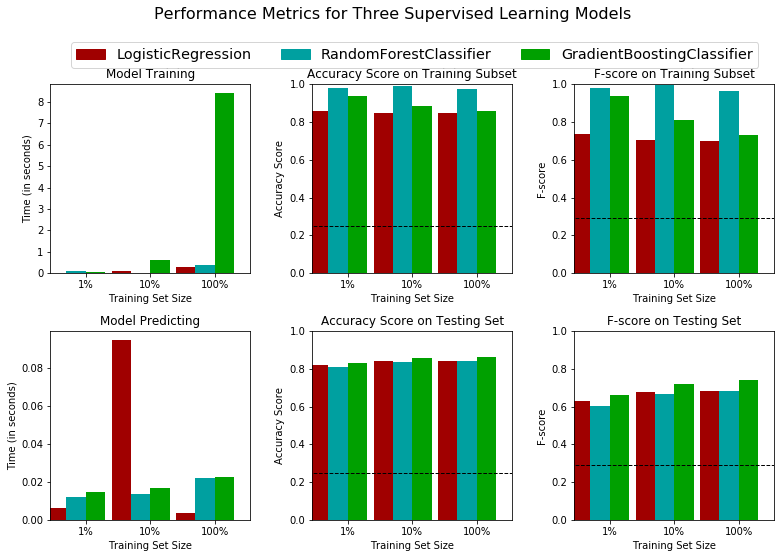

In [11]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from time import time

clf_A = LogisticRegression(random_state=42)
clf_B = RandomForestClassifier(random_state=42)
clf_C = GradientBoostingClassifier(random_state=42)


samples_100 = int(len(y_train)*1.00)
samples_10 = int(len(y_train)*0.10)
samples_1 = int(len(y_train)*0.01)

# Collect results on the learners
results = {}
for clf in [clf_A, clf_B, clf_C]:
    clf_name = clf.__class__.__name__
    results[clf_name] = {}
    for i, samples in enumerate([samples_1, samples_10, samples_100]):
        results[clf_name][i] = \
        train_predict(clf, samples, X_train, y_train, X_test, y_test)

# Run metrics visualization for the three supervised learning models chosen
vs.evaluate(results, accuracy, fscore)

## Model Optimization

Following the initial evaluation, I selected the most promising supervised learning algorithm for further optimization. The selection was based on three key considerations:

- **Predictive performance:** Testing F0.5 score when trained on 100% of the training data.
- **Computational efficiency:** Training and prediction times relative to the other algorithms.
- **Model suitability:** The algorithm's ability to handle the dataset's characteristics and generalize to unseen observations.

### Model Selection

Based on the evaluation results, I believe Gradient Boosting is the most appropriate model for CharityML's goal of identifying individuals who make more than $50,000. When using 100% of the training data, Gradient Boosting achieved the highest testing F-score of approximately 0.69, compared with approximately 0.66 for Random Forest and 0.65 for Logistic Regression. Although Gradient Boosting had the longest training time at approximately 5.9 seconds, its prediction time was only about 0.02 seconds, making it reasonably efficient for making predictions.

Gradient Boosting is also a good fit for the Census data because the dataset contains many demographic and socioeconomic features that may have complex and nonlinear relationships with income. Unlike Logistic Regression, which is more limited to linear relationships, Gradient Boosting can capture more complicated patterns in the data. Therefore, despite its longer training time, Gradient Boosting is the strongest choice because it produced the highest testing F-score while maintaining a relatively fast prediction time.

The selected model was subsequently optimized using grid search with cross-validation to identify hyperparameter settings that could improve its F0.5 score.

### How Gradient Boosting Works

Gradient Boosting works by combining multiple small decision trees to make increasingly accurate predictions. The model begins with an initial prediction and then builds additional trees that focus on correcting the mistakes made by the previous ones. Each new tree contributes a small adjustment, gradually improving the model's overall performance.

For CharityML, the model learns patterns from historical census data, examining characteristics such as age, education, occupation, and working hours to identify relationships with income levels. When presented with a new individual, the trained model combines the contributions of its decision trees to predict whether that person is likely to earn more than \$50,000. This helps CharityML prioritize individuals who may be suitable candidates for donor outreach.

In [12]:

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, fbeta_score, accuracy_score
from sklearn.ensemble import GradientBoostingClassifier

clf = GradientBoostingClassifier(random_state=42)


parameters = {
    'n_estimators':[50,100,150]
}


scorer = make_scorer(fbeta_score, beta=0.5)


grid_obj = GridSearchCV(clf, parameters, scoring=scorer)


grid_fit = grid_obj.fit(X_train, y_train)

# Get the estimator
best_clf = grid_fit.best_estimator_

# Make predictions using the unoptimized and model
predictions = (clf.fit(X_train, y_train)).predict(X_test)
best_predictions = best_clf.predict(X_test)

# Report the before-and-afterscores
print("Unoptimized model\n------")
print("Accuracy score on testing data: {:.4f}".format(accuracy_score(y_test, predictions)))
print("F-score on testing data: {:.4f}".format(fbeta_score(y_test, predictions, beta = 0.5)))
print("\nOptimized Model\n------")
print("Final accuracy score on the testing data: {:.4f}".format(accuracy_score(y_test, best_predictions)))
print("Final F-score on the testing data: {:.4f}".format(fbeta_score(y_test, best_predictions, beta = 0.5)))

Unoptimized model
------
Accuracy score on testing data: 0.8630
F-score on testing data: 0.7395

Optimized Model
------
Final accuracy score on the testing data: 0.8658
Final F-score on the testing data: 0.7435


#### Results:

|     Metric     | Unoptimized Model | Optimized Model |
| :------------: | :---------------: | :-------------: | 
| Accuracy Score |     0.8630        |     0.8658      |
| F-score        |     0.7395        |     0.7435      |


### Model Optimization Results

The optimized Gradient Boosting model achieved a testing accuracy of **86.58%** and an F0.5 score of **0.7435**, compared with 86.30% accuracy and an F0.5 score of 0.7395 for the untuned model. Although hyperparameter tuning produced only a modest improvement, the optimized model demonstrated slightly stronger predictive performance on the testing dataset.

Compared with the naive predictor, which achieved 24.78% accuracy and an F0.5 score of 0.2917, the optimized model performed substantially better. These results demonstrate the effectiveness of Gradient Boosting in identifying individuals earning more than \$50,000 while placing greater emphasis on reducing false-positive predictions.

### Feature Importance: Initial Hypotheses

Before examining the model's feature importance results, I hypothesized that the five most influential predictors of income would be **capital gain, education level, occupation, age, and hours worked per week**, in that order.

Capital gain may indicate investment income or additional financial resources, while education and occupation are associated with earning potential. Age may reflect career experience and progression, and hours worked per week may provide insight into employment patterns and earning capacity.

Although these characteristics do not necessarily cause higher income, I expected them to provide useful predictive information for classifying individuals by income level.

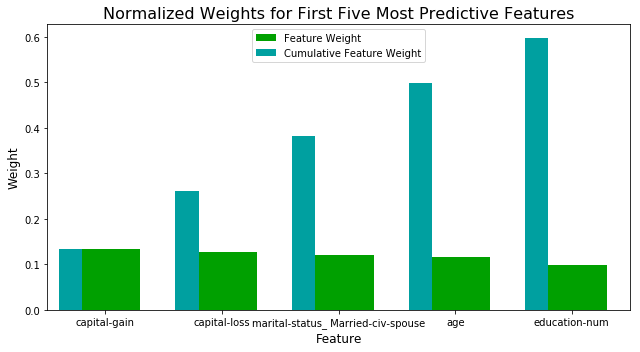

In [13]:
from sklearn.ensemble import GradientBoostingClassifier

model = GradientBoostingClassifier(random_state=42)
model.fit(X_train, y_train)

importances = model.feature_importances_


vs.feature_plot(importances, X_train, y_train)

### Feature Importance: Hypotheses vs. Results

My initial predictions were partially supported by the model's feature importance results. Of the five features I expected to be most influential, three appeared among the model's top predictors: **education level, capital gain, and age**. The remaining two important features were marital status (`marital-status_Married-civ-spouse`) and capital loss.

The importance of marital status and capital loss was unexpected, as I initially anticipated that occupation and hours worked per week would have greater predictive influence. Marital status may capture socioeconomic patterns associated with income, while capital loss may provide additional information about financial and investment activity.

These findings highlight the value of evaluating feature importance rather than relying solely on initial assumptions. However, feature importance reflects the model's predictive relationships and should not be interpreted as evidence of causation.

### Feature Selection
How does a model perform if we only use a subset of all the available features in the data? With less features required to train, the expectation is that training and prediction time is much lower — at the cost of performance metrics. From the visualization above, we see that the top five most important features contribute more than half of the importance of **all** features present in the data. This hints that we can attempt to *reduce the feature space* and simplify the information required for the model to learn. The code cell below will use the same optimized model you found earlier, and train it on the same training set *with only the top five important features*. 

In [14]:
# Import functionality for cloning a model
from sklearn.base import clone

# Reduce the feature space
X_train_reduced = X_train[X_train.columns.values[(np.argsort(importances)[::-1])[:5]]]
X_test_reduced = X_test[X_test.columns.values[(np.argsort(importances)[::-1])[:5]]]

# Train on the "best" model found from grid search earlier
clf = (clone(best_clf)).fit(X_train_reduced, y_train)

# Make new predictions
reduced_predictions = clf.predict(X_test_reduced)

# Report scores from the final model using both versions of data
print("Final Model trained on full data\n------")
print("Accuracy on testing data: {:.4f}".format(accuracy_score(y_test, best_predictions)))
print("F-score on testing data: {:.4f}".format(fbeta_score(y_test, best_predictions, beta = 0.5)))
print("\nFinal Model trained on reduced data\n------")
print("Accuracy on testing data: {:.4f}".format(accuracy_score(y_test, reduced_predictions)))
print("F-score on testing data: {:.4f}".format(fbeta_score(y_test, reduced_predictions, beta = 0.5)))

Final Model trained on full data
------
Accuracy on testing data: 0.8658
F-score on testing data: 0.7435

Final Model trained on reduced data
------
Accuracy on testing data: 0.8588
F-score on testing data: 0.7263


### Impact of Feature Selection

To evaluate whether a simpler model could maintain comparable predictive performance, I retrained the optimized Gradient Boosting model using only the five most important features.

The model trained on all features achieved an accuracy of **86.58%** and an F0.5 score of **0.7435**, compared with **85.88%** accuracy and an F0.5 score of **0.7263** when using only five features.

Although reducing the feature set slightly decreased predictive performance, the reduced model remained relatively competitive, with accuracy declining by only 0.70 percentage points.

If computational efficiency were a priority, the reduced feature set could be a practical alternative because it requires fewer input variables. However, I would compare actual training times before concluding that the reduced model provides a meaningful efficiency advantage.

Overall, I would retain the full feature set when predictive performance is the primary objective, while considering the reduced feature set if simplicity and computational efficiency become more important.

In [15]:
!!jupyter nbconvert *.ipynb

['[NbConvertApp] Converting notebook finding_donors- Github.ipynb to html',
 '[NbConvertApp] Writing 459391 bytes to finding_donors- Github.html',
 '[NbConvertApp] Converting notebook finding_donors.ipynb to html',
 '[NbConvertApp] Writing 347285 bytes to finding_donors.html']